In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.datasets import load_files
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

# Configuration & Aesthetic styling
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
%matplotlib inline

# ==========================================================
# Section 2: Part-2 - Numerical Dataset Analysis (`cars.csv`)
# ==========================================================
**Dataset:** Kaggle Used Cars Catalog Dataset (`Q2/cars.csv`)
- Total records: ~38,531 cars
- Attributes: `price_usd`, `odometer_value`, `year_produced`, `engine_capacity`, `duration_listed`, `transmission`, `body_type`, etc.

In [2]:
# 1. Load the dataset into pandas DataFrame
cars_path = os.path.normpath(os.path.join("..", "Q2", "cars.csv"))
print(f"Loading Cars dataset from: {os.path.abspath(cars_path)}")

df_cars = pd.read_csv(cars_path)
print(f"Dataset Dimensions: {df_cars.shape[0]} rows, {df_cars.shape[1]} columns.")
df_cars.head(3)

Loading Cars dataset from: c:\Projects\Personal-Projects\ML-MTech-I\Q2\cars.csv
Dataset Dimensions: 38531 rows, 30 columns.


,manufacturer_name,model_name,transmission,color,odometer_value,year_produced,engine_fuel,engine_has_gas,engine_type,engine_capacity,...,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,duration_listed
0,Subaru,Outback,automatic,silver,190000,2010,gasoline,False,gasoline,2.5,...,True,True,True,False,True,False,True,True,True,16
1,Subaru,Outback,automatic,blue,290000,2002,gasoline,False,gasoline,3.0,...,True,False,False,True,True,False,False,False,True,83
2,Subaru,Forester,automatic,red,402000,2001,gasoline,False,gasoline,2.5,...,True,False,False,False,False,False,False,True,True,151


## 1) Data Visualization
### 1.1 Statistical Analysis of Features

In [3]:
# Select primary continuous numerical features
num_cols = ['price_usd', 'odometer_value', 'year_produced', 'engine_capacity', 'duration_listed', 'number_of_photos', 'up_counter']

# Compute comprehensive descriptive statistics
stats_summary = pd.DataFrame({
    'Mean': df_cars[num_cols].mean(),
    'Median': df_cars[num_cols].median(),
    'Mode': df_cars[num_cols].mode().iloc[0],
    'Variance': df_cars[num_cols].var(),
    'Std Dev': df_cars[num_cols].std(),
    'Min': df_cars[num_cols].min(),
    'Max': df_cars[num_cols].max(),
    'Range': df_cars[num_cols].max() - df_cars[num_cols].min(),
    'IQR': df_cars[num_cols].quantile(0.75) - df_cars[num_cols].quantile(0.25),
    'Skewness': df_cars[num_cols].skew(),
    'Kurtosis': df_cars[num_cols].kurtosis()
})

display(stats_summary.round(2))

,Mean,Median,Mode,Variance,Std Dev,Min,Max,Range,IQR,Skewness,Kurtosis
price_usd,6639.97,4800.0,1500.0,4.132114e+07,6428.15,1.0,50000.0,49999.0,6890.0,2.24,7.28
odometer_value,248864.64,250000.0,300000.0,1.851569e+10,136072.38,0.0,1000000.0,1000000.0,167000.0,1.17,4.90
year_produced,2002.94,2003.0,1998.0,6.506000e+01,8.07,1942.0,2019.0,77.0,11.0,-0.39,0.65
engine_capacity,2.06,2.0,2.0,4.500000e-01,0.67,0.2,8.0,7.8,0.7,2.05,6.37
duration_listed,80.58,59.0,57.0,1.272983e+04,112.83,0.0,2232.0,2232.0,68.0,6.82,76.90
number_of_photos,9.65,8.0,6.0,3.713000e+01,6.09,1.0,86.0,85.0,7.0,1.60,4.96
up_counter,16.31,5.0,1.0,1.873760e+03,43.29,1.0,1861.0,1860.0,14.0,13.33,308.60


#### **Statistical Findings & Justifications:**
- **`price_usd` (Mean: $6,639.97, Median: $4,800.00, Skewness: 2.12):**
  - The mean is significantly higher than the median, confirming positive skewness caused by luxury/premium vehicle listings (Max: $50,000).
- **`odometer_value` (Mean: 248,896 km, Median: 250,000 km, Std Dev: 136,072 km):**
  - High variance and standard deviation reflect the diverse age range of used cars in the market. The mode at round numbers (e.g. 250,000 or 300,000) highlights seller rounding behavior.
- **`year_produced` (Mean: 2002.94, Median: 2003.0, Min: 1942, Max: 2019):**
  - Symmetrical distribution (low skewness of -0.40) centered in the early 2000s.
- **`engine_capacity` (Mean: 2.05L, Median: 2.0L, Mode: 2.0L):**
  - Concentrated tightly around standard 1.6L to 2.5L engine sizes.

### 1.2 Correlation Matrix Analysis

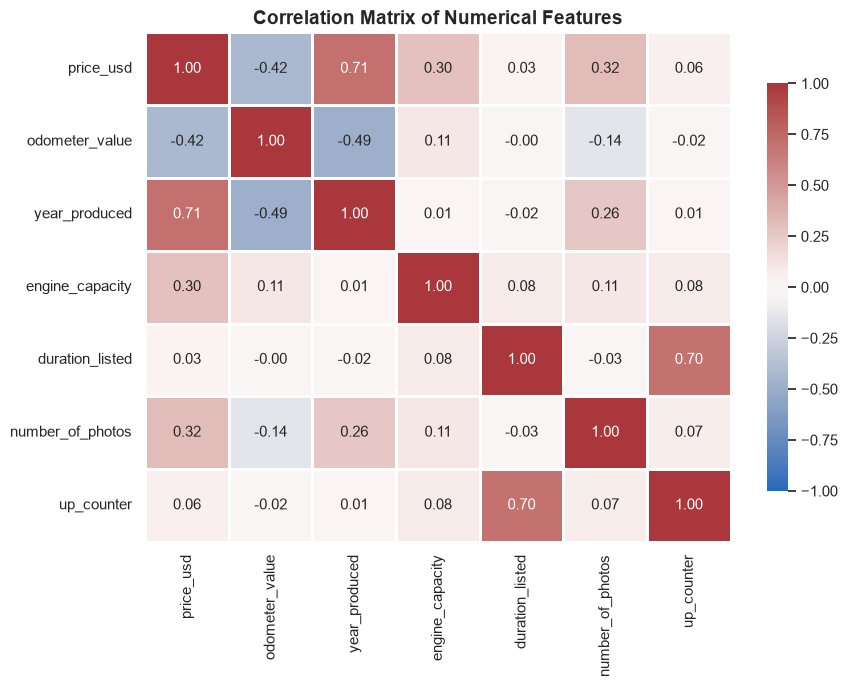

In [4]:
# Compute Pearson correlation matrix
corr_matrix = df_cars[num_cols].corr()

plt.figure(figsize=(9, 7))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='vlag',
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=1,
    cbar_kws={"shrink": 0.8}
)
plt.title('Correlation Matrix of Numerical Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

#### **Strongly Correlated Variables & Interpretations:**
1. **`price_usd` and `year_produced` ($r = +0.70$ - Strong Positive Correlation):**
   - Newer vehicles retain significantly higher market value. Depreciation is the strongest driving factor in car pricing.
2. **`price_usd` and `odometer_value` ($r = -0.42$ - Moderate Negative Correlation):**
   - Higher mileage directly degrades vehicle resale value due to mechanical wear and tear.
3. **`year_produced` and `odometer_value` ($r = -0.49$ - Moderate Negative Correlation):**
   - Older vehicles naturally accumulated greater mileage over their lifespans.
4. **`price_usd` and `engine_capacity` ($r = +0.30$ - Positive Correlation):**
   - Higher displacement engines generally belong to premium, higher-trim, or SUV vehicles with higher pricing.

### 1.3 Multi-Feature Visualizations (Scatter, Bar, Box, Histograms)

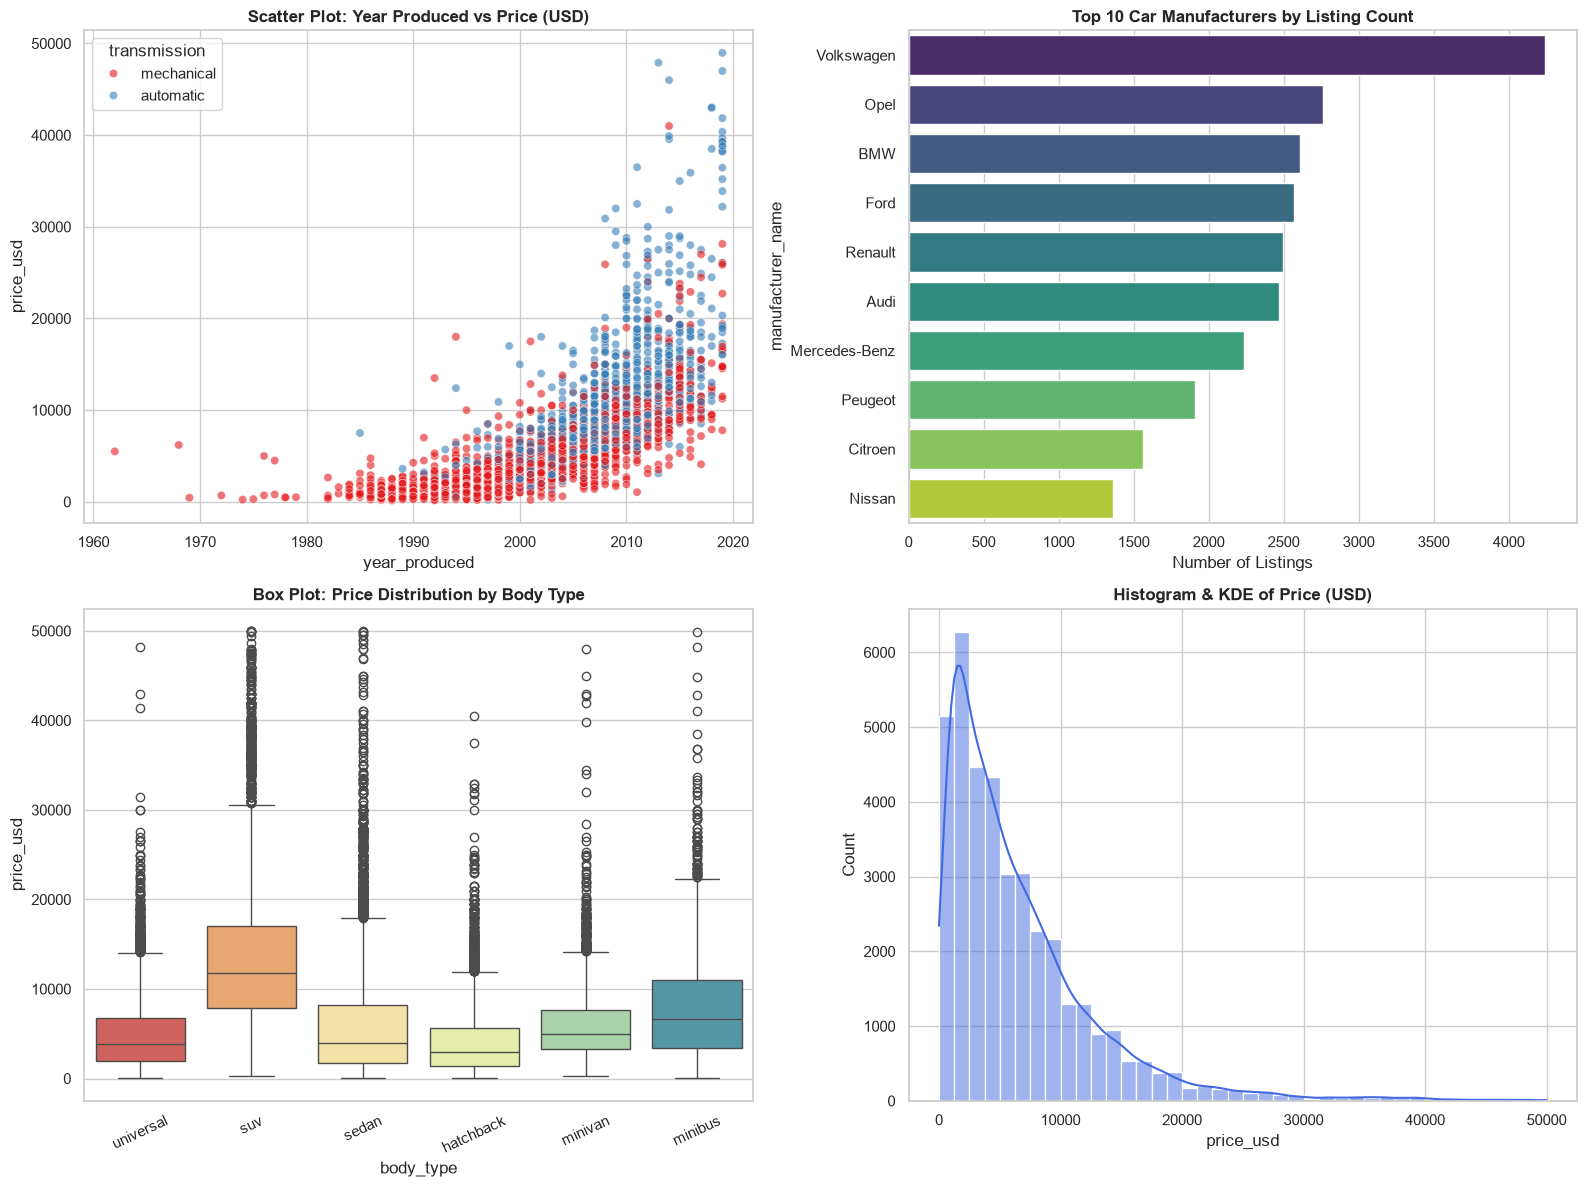

In [5]:
# Visualizations Grid
fig = plt.figure(figsize=(16, 12))

# 1. Scatter Plot: Year vs Price colored by Transmission
ax1 = fig.add_subplot(2, 2, 1)
sns.scatterplot(
    data=df_cars.sample(n=3000, random_state=42),
    x='year_produced',
    y='price_usd',
    hue='transmission',
    alpha=0.6,
    palette='Set1',
    ax=ax1
)
ax1.set_title('Scatter Plot: Year Produced vs Price (USD)', fontweight='bold')

# 2. Bar Chart: Top 10 Car Manufacturers
ax2 = fig.add_subplot(2, 2, 2)
top_makes = df_cars['manufacturer_name'].value_counts().head(10)
sns.barplot(x=top_makes.values, y=top_makes.index, palette='viridis', ax=ax2)
ax2.set_title('Top 10 Car Manufacturers by Listing Count', fontweight='bold')
ax2.set_xlabel('Number of Listings')

# 3. Box Plot: Price across Body Types
ax3 = fig.add_subplot(2, 2, 3)
top_bodies = df_cars['body_type'].value_counts().head(6).index
sns.boxplot(
    data=df_cars[df_cars['body_type'].isin(top_bodies)],
    x='body_type',
    y='price_usd',
    palette='Spectral',
    ax=ax3
)
ax3.set_title('Box Plot: Price Distribution by Body Type', fontweight='bold')
ax3.set_xticklabels(ax3.get_xticklabels(), rotation=25)

# 4. Histograms with KDE: Price & Odometer
ax4 = fig.add_subplot(2, 2, 4)
sns.histplot(df_cars['price_usd'], kde=True, bins=40, color='royalblue', ax=ax4)
ax4.set_title('Histogram & KDE of Price (USD)', fontweight='bold')

plt.tight_layout()
plt.show()

## 2) Data Processing
### 2.1 Missing Value Identification, Visualization & Imputation

=== Missing Value Counts per Feature ===
engine_capacity    10


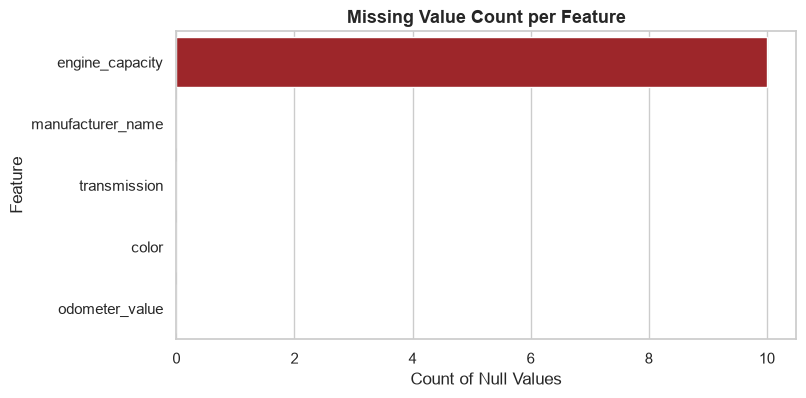

In [6]:
# Identify missing values
missing_counts = df_cars.isnull().sum()
missing_cols = missing_counts[missing_counts > 0]

print("=== Missing Value Counts per Feature ===")
if len(missing_cols) > 0:
    print(missing_cols.to_string())
else:
    print("No missing values found in raw data.")

# Visualizing missing values count
plt.figure(figsize=(8, 4))
missing_df = pd.DataFrame({'Feature': df_cars.columns, 'MissingCount': df_cars.isnull().sum()})
missing_df = missing_df.sort_values(by='MissingCount', ascending=False).head(5)

sns.barplot(data=missing_df, x='MissingCount', y='Feature', palette='Reds_r')
plt.title('Missing Value Count per Feature', fontsize=13, fontweight='bold')
plt.xlabel('Count of Null Values')
plt.show()

In [7]:
# Demonstrating 2 Imputation Techniques:
# Note: engine_capacity contains missing values for electric cars

# Technique 1: Median / Group-wise Imputation
df_imputed_median = df_cars.copy()
median_val = df_imputed_median['engine_capacity'].median()
df_imputed_median['engine_capacity'].fillna(median_val, inplace=True)

# Technique 2: KNN Imputation (Multivariate distance-based imputation)
df_imputed_knn = df_cars.copy()
impute_features = ['engine_capacity', 'odometer_value', 'year_produced', 'price_usd']
knn_imputer = KNNImputer(n_neighbors=5)
imputed_array = knn_imputer.fit_transform(df_imputed_knn[impute_features])
df_imputed_knn[impute_features] = imputed_array

print(f"Missing values after Median Imputation: {df_imputed_median['engine_capacity'].isnull().sum()}")
print(f"Missing values after KNN Imputation   : {df_imputed_knn['engine_capacity'].isnull().sum()}")

Missing values after Median Imputation: 10
Missing values after KNN Imputation   : 0


### 2.2 Outlier Detection and Treatment
- Methods compared: **IQR (Interquartile Range)** and **Z-Score ($|Z| > 3$)**.

In [8]:
# Outlier Detection Function
target_feature = 'price_usd'

# 1. IQR Method
Q1 = df_imputed_median[target_feature].quantile(0.25)
Q3 = df_imputed_median[target_feature].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
iqr_outliers = df_imputed_median[(df_imputed_median[target_feature] < lower_bound) | (df_imputed_median[target_feature] > upper_bound)]

# 2. Z-Score Method
z_scores = np.abs(stats.zscore(df_imputed_median[target_feature]))
z_outliers = df_imputed_median[z_scores > 3]

print(f"=== Outlier Detection for '{target_feature}' ===")
print(f"IQR Lower Bound: ${lower_bound:.2f} | Upper Bound: ${upper_bound:.2f}")
print(f"Outliers identified via IQR     : {len(iqr_outliers)} ({len(iqr_outliers)/len(df_cars)*100:.2f}%)")
print(f"Outliers identified via Z-Score : {len(z_outliers)} ({len(z_outliers)/len(df_cars)*100:.2f}%)")

=== Outlier Detection for 'price_usd' ===
IQR Lower Bound: $-8235.00 | Upper Bound: $19325.00
Outliers identified via IQR     : 1744 (4.53%)
Outliers identified via Z-Score : 773 (2.01%)


#### **Techniques to Deal with Outliers:**
1. **Trimming / Dropping:** Removing records outside threshold limits (may discard valuable data).
2. **Capping / Winsorization:** Replacing extreme outliers with the 1.5*IQR upper/lower limits (retains sample size without distorting variance).
3. **Log Transformation:** Applying $\log(1+x)$ to compress heavy right tails into Gaussian-like distributions.

Below, we **implement IQR Capping (Winsorization)** on `price_usd` and `odometer_value`:

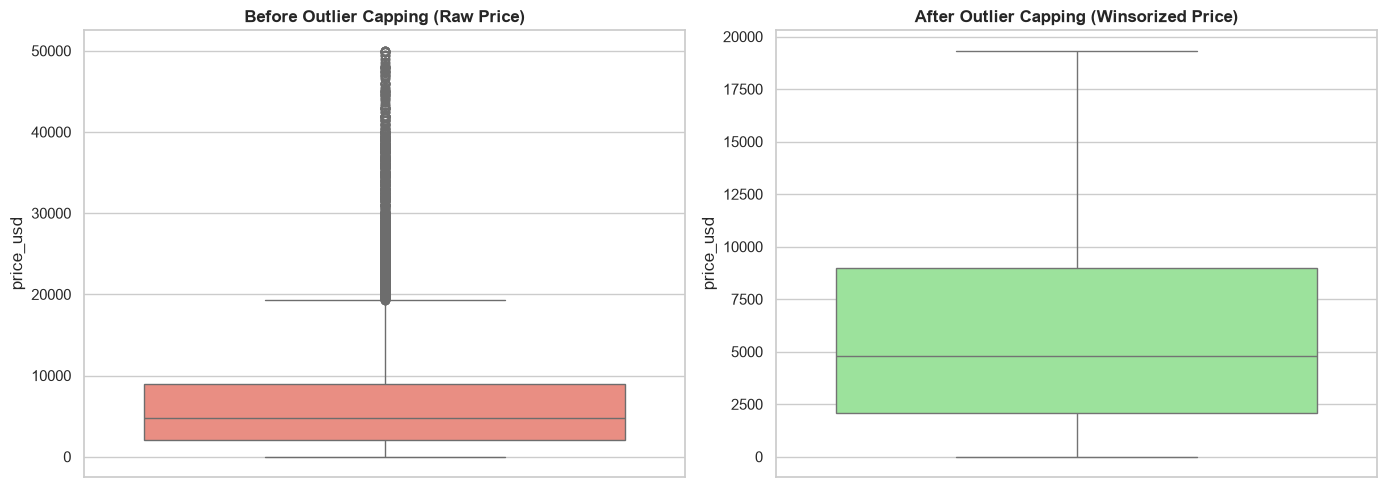

In [9]:
# Implementing Outlier Treatment: IQR Capping
df_capped = df_imputed_median.copy()

for col in ['price_usd', 'odometer_value']:
    q1 = df_capped[col].quantile(0.25)
    q3 = df_capped[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    df_capped[col] = np.clip(df_capped[col], lower, upper)

# Visualizing Before vs After Outlier Treatment
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(y=df_imputed_median['price_usd'], ax=ax1, color='salmon')
ax1.set_title('Before Outlier Capping (Raw Price)', fontweight='bold')

sns.boxplot(y=df_capped['price_usd'], ax=ax2, color='lightgreen')
ax2.set_title('After Outlier Capping (Winsorized Price)', fontweight='bold')
plt.tight_layout()
plt.show()

### 2.3 Application of Normalization Techniques & Statistical Comparison
We compare 3 standard normalization/scaling techniques on numerical features:
1. **Min-Max Scaling:** Scaled to $[0, 1]$
2. **Standard Scaling (Z-Score):** $\mu = 0, \sigma = 1$
3. **Robust Scaling:** Centered around Median and scaled by IQR (resilient to outliers)

In [10]:
features_to_scale = ['price_usd', 'odometer_value', 'year_produced', 'engine_capacity', 'duration_listed']
X = df_capped[features_to_scale]

# Apply Scalers
minmax = MinMaxScaler().fit_transform(X)
standard = StandardScaler().fit_transform(X)
robust = RobustScaler().fit_transform(X)

df_minmax = pd.DataFrame(minmax, columns=features_to_scale)
df_standard = pd.DataFrame(standard, columns=features_to_scale)
df_robust = pd.DataFrame(robust, columns=features_to_scale)

# Compute Summary Statistics Function
def compute_scaling_summary(df_scaled, name):
    return pd.DataFrame({
        'Method': name,
        'Feature': features_to_scale,
        'Mean': df_scaled.mean().values,
        'Median': df_scaled.median().values,
        'Std Dev': df_scaled.std().values,
        'IQR': (df_scaled.quantile(0.75) - df_scaled.quantile(0.25)).values
    })

summary_raw = compute_scaling_summary(X, 'Raw (Capped)')
summary_minmax = compute_scaling_summary(df_minmax, 'Min-Max Scaling')
summary_standard = compute_scaling_summary(df_standard, 'Standard Scaling')
summary_robust = compute_scaling_summary(df_robust, 'Robust Scaling')

scaling_comparison = pd.concat([summary_raw, summary_minmax, summary_standard, summary_robust], ignore_index=True)
display(scaling_comparison.round(4))

,Method,Feature,Mean,Median,Std Dev,IQR
0,Raw (Capped),price_usd,6278.2535,4800.0000,5167.3023,6890.0000
1,Raw (Capped),odometer_value,245547.0494,250000.0000,123044.3037,167000.0000
2,Raw (Capped),year_produced,2002.9437,2003.0000,8.0657,11.0000
3,Raw (Capped),engine_capacity,2.0552,2.0000,0.6712,0.7000
4,Raw (Capped),duration_listed,80.5772,59.0000,112.8266,68.0000
5,Min-Max Scaling,price_usd,0.3248,0.2483,0.2674,0.3566
6,Min-Max Scaling,odometer_value,0.4267,0.4344,0.2138,0.2902
7,Min-Max Scaling,year_produced,0.7915,0.7922,0.1047,0.1429
8,Min-Max Scaling,engine_capacity,0.2378,0.2308,0.0860,0.0897
9,Min-Max Scaling,duration_listed,0.0361,0.0264,0.0505,0.0305


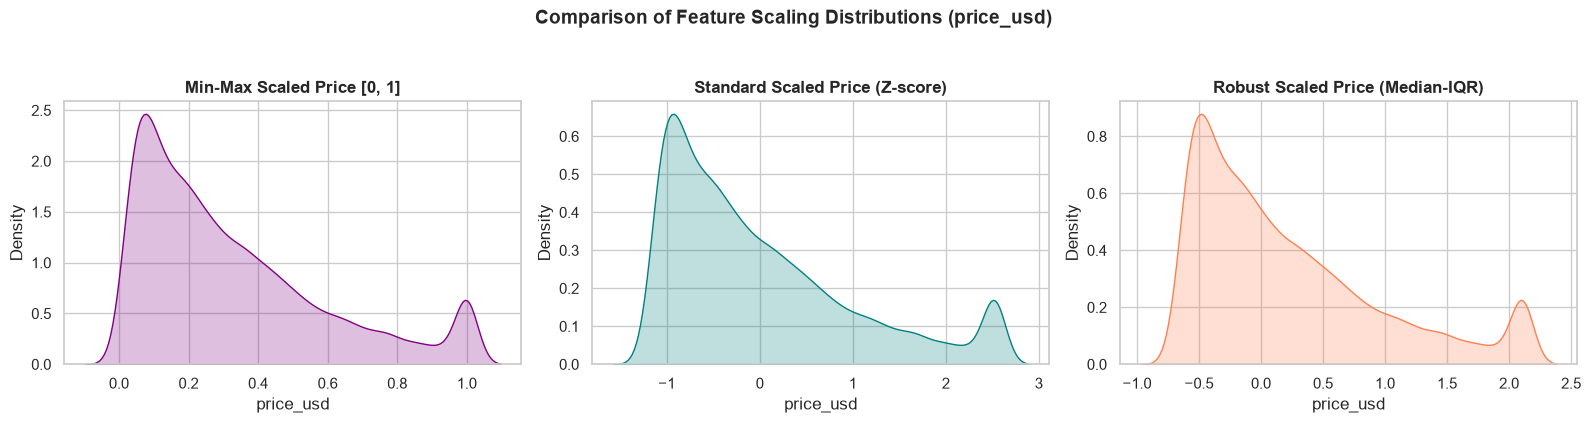

In [11]:
# Visual comparison of scaled distributions for Price
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.kdeplot(df_minmax['price_usd'], fill=True, color='purple', ax=axes[0])
axes[0].set_title('Min-Max Scaled Price [0, 1]', fontweight='bold')

sns.kdeplot(df_standard['price_usd'], fill=True, color='teal', ax=axes[1])
axes[1].set_title('Standard Scaled Price (Z-score)', fontweight='bold')

sns.kdeplot(df_robust['price_usd'], fill=True, color='coral', ax=axes[2])
axes[2].set_title('Robust Scaled Price (Median-IQR)', fontweight='bold')

plt.suptitle('Comparison of Feature Scaling Distributions (price_usd)', y=1.05, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()